# Cierre de la fase 1 · T33 y T35–T39

**Pregunta.** ¿Qué decisiones de operación y localización sostienen la recomendación después de pasar de cobertura espacial a servicio e inventario?

Se comparan las mismas salidas elegibles, con ajustes de diseño del 1 al 21 de febrero y evaluación del 22 al 28. Cada periodo reinicia la flota desde el stock de diseño. El caso habitual usa las ubicaciones de T28, el stock y los anclajes de T32 y la flota de T34. Las variantes mantienen el total de recursos. La asignación y los rechazos salen del mismo simulador.

**Reproducción.** Desde la raíz, con el entorno del proyecto, ejecutar `python consumo/modelo_a.py` y `python movilidad/cierre.py` después de T21, T28 y T32. Los comandos forman parte de `ejecutar_todo.py`. Este notebook lee sus tablas y genera la figura de síntesis.

In [1]:
import pandas as pd
from IPython.display import display

from comun.figuras import guardar_figura, plt
from redes import leer

reb, soc, zonas, cierres, redes = (leer(n) for n in (
    "T33_politicas", "T35_carga", "T37_zonas", "T38_cierres", "T39_redes"))
habitual = redes.loc[redes["red"].eq("habitual")]
flota, = redes["flota"].unique()
anclajes, = redes["anclajes"].unique()
assert flota == habitual.iloc[0]["flota"] and anclajes == habitual.iloc[0]["anclajes"]

## T33 · Coste y servicio del rebalanceo

En cada corte de las 04:00 se respetan los límites de 0, 100 y 220 unidades por noche de T14. La regla habitual repone primero el mayor déficit. La alternativa usa la proporción de jornadas de ajuste en que el saldo acumulado sin restricciones habría requerido una unidad más que el stock disponible. Los empates favorecen el mayor déficit y el orden estable de las estaciones. En ambas reglas dona la estación con excedente más próxima. Es una estimación de beneficio marginal basada en las salidas de ajuste y el balance de cada estación.

La regla de decisión conserva el criterio de T34 del 95 % de viajes cubiertos atendidos en ajuste y escoge la combinación con menos kilómetros equivalentes entre las que cumplen. Los kilómetros suman distancias entre estaciones multiplicadas por el rodeo de T15. Los traslados son instantáneos al corte del modelo. La demanda del siguiente día de servicio se cuenta desde las 04:00, y se guardan sus rechazos junto al déficit de cada noche.

In [2]:
objetivo_servicio = 95
ajuste = reb.loc[reb["periodo"].eq("ajuste")]
factibles = ajuste.loc[ajuste["pct_atendidos_cubiertos"].ge(objetivo_servicio)]
display(factibles.sort_values(["km_rebalanceo", "n_atendido"], ascending=[True, False]).head(1))
display(reb[["periodo", "politica", "limite", "n_atendido", "n_sin_patinete", "n_sin_anclaje",
             "km_rebalanceo", "deficit_medio"]].round(2))

,periodo,politica,limite,flota,anclajes,rebalanceo_max,desvio,solicitudes,cubiertas,n_atendido,...,pct_atendidos_total,viajes_con_desvio,desvio_medio_m,dias,viajes_por_patinete_dia,pct_tiempo_en_viaje,patinetes_movidos,km_rebalanceo,noches,deficit_medio
1,ajuste,deficit,100,400,966,100,True,16756,13409,12750,...,76.092146,298,85.329595,21.008252,1.517261,1.168356,1969,2416.835994,20,10.15


,periodo,politica,limite,n_atendido,n_sin_patinete,n_sin_anclaje,km_rebalanceo,deficit_medio
0,ajuste,deficit,0,11379,1414,616,0.00,145.60
1,ajuste,deficit,100,12750,472,187,2416.84,10.15
2,ajuste,deficit,220,12790,456,163,2988.91,0.00
3,ajuste,beneficio,0,11379,1414,616,0.00,145.60
4,ajuste,beneficio,100,12756,462,191,2430.25,8.95
5,ajuste,beneficio,220,12790,456,163,2909.82,0.00
6,reservada,deficit,0,4302,517,182,0.00,133.00
7,reservada,deficit,100,4670,259,72,806.32,9.33
8,reservada,deficit,220,4681,253,67,985.91,0.00
9,reservada,beneficio,0,4302,517,182,0.00,133.00


## T35 · Estado de carga

El modelo A (T40) calcula 13,5 Wh/km para la distancia registrada de cada viaje. La batería parte llena al comienzo de cada periodo. Cada anclaje ofrece carga lineal mientras tiene un patinete, con 7 h para reponer los 576 Wh nominales. Entre unidades suficientes se utiliza la de menor carga para reservar las más cargadas. Se añade una sensibilidad con el 20 % de reserva al terminar el viaje para comprobar un margen frente a errores de consumo. Se distingue falta de batería de falta de patinete o anclaje.

La energía de tracción se concilia con la recargada y la pendiente al cierre. Es un contraste con carga disponible por anclaje. La limitación de potencia y una política de carga dependiente de la energía solar se evalúan en la fase de recarga.

In [3]:
display(soc[["periodo", "caso", "n_atendido", "n_sin_bateria", "traccion_kwh", "recargada_kwh",
             "pendiente_kwh"]].round(3))

,periodo,caso,n_atendido,n_sin_bateria,traccion_kwh,recargada_kwh,pendiente_kwh
0,ajuste,inventario,12750,0,NaN,NaN,NaN
1,ajuste,carga,12750,0,349.535,349.427,0.107
2,ajuste,reserva20,12750,0,349.535,349.427,0.107
3,reservada,inventario,4670,0,NaN,NaN,NaN
4,reservada,carga,4670,0,131.301,131.235,0.067
5,reservada,reserva20,4670,0,131.301,131.235,0.067


## T36 · Cobertura y flujos operativos en el mapa

En cada celda H3 de origen se publican las solicitudes, los viajes con cobertura en ambos extremos y los atendidos. Los flujos cuentan asignaciones aceptadas entre estaciones tras desvíos por inventario y anclajes. Se incluyen flujos hacia la misma estación en las tablas. El mapa dibuja el subconjunto de pares entre estaciones distintas, con detalle al seleccionar una estación.

[Mapa 3D de la red habitual](https://javiersaguar.github.io/PIDS-Proyecto3/#/mapa/validacion/ajuste/ambos/lscp_r300_k159/operacion)

In [4]:
celdas = leer("T36_cobertura_operativa")
agrupado = celdas.groupby("periodo")[["viajes", "cubiertos", "atendidos"]].sum()
for c, r in zip(agrupado, ["solicitudes", "cubiertas", "n_atendido"]):
    assert agrupado[c].equals(habitual.set_index("periodo")[r].reindex(agrupado.index))
display(agrupado)

,viajes,cubiertos,atendidos
periodo,,,
ajuste,16756,13409,12750
reservada,6614,5001,4670


## T37 · Acceso territorial con el mismo presupuesto

La unidad de análisis es la zona urbanística de origen de T21, con el viaje completo como unidad de cobertura. Se exige un mínimo de 100 salidas del ajuste para limitar a cinco puntos el error estándar binomial máximo de la tasa como referencia descriptiva. Las salidas fuera de la zonificación se documentan y siguen en el indicador global. Se toman las zonas del cuartil inferior, redondeado hacia arriba y ordenado por tasa y código, y se les da el mismo peso. Eso evita que la zona con mayor demanda absorba por sí sola el objetivo.

Se evalúa cada intercambio de un emplazamiento abierto y uno cerrado de T24. Se prioriza la mayor mejora de la media de las tasas sin reducir el número global de viajes cubiertos del ajuste. Los empates favorecen más cobertura global y el orden por identificador. Se admiten hasta cinco pasos, una intervención acotada como en T38. El resultado es un óptimo local del proceso y se evalúa con las zonas prioritarias y las posiciones ya fijadas.

In [5]:
prioritarias = zonas.loc[zonas["prioritaria"]]
display(prioritarias.groupby(["periodo", "red"]).agg(zonas=("zona", "size"),
    salidas=("viajes", "sum"), cubiertos=("cubiertos", "sum"), media_pct=("pct", "mean")).round(2))
display(leer("T37_T38_intercambios"))

zonas  salidas  cubiertos  media_pct
periodo   red                                           
ajuste    equidad       8     1655        912      57.45
          habitual      8     1655        842      51.95
reservada equidad       8      700        366      51.92
          habitual      8      700        327      45.61

,paso,sale,entra,valor_antes,valor_despues,viajes_cubiertos,red
0,1,891e8050133ffff,891e8050137ffff,4.156183,4.284389,13418,equidad
1,2,891e8050c83ffff,891e8050307ffff,4.284389,4.439355,13412,equidad
2,3,891e8050c47ffff,891e80521abffff,4.439355,4.555624,13409,equidad
3,4,891e8050177ffff,891e805012bffff,4.555624,4.589812,13410,equidad
4,5,891e8052ac3ffff,891e8052ad7ffff,4.589812,4.596348,13410,equidad
5,1,891e805056bffff,891e80500a7ffff,2003.000000,2037.000000,13406,redundante
6,2,891e8052a0fffff,891e8052a0bffff,2037.000000,2040.000000,13405,redundante


## T38 · Robustez ante cierres

El día de ajuste se elige por volumen de viajes cubiertos en la punta de tarde T12. Se ordenan las estaciones por el número de esos viajes que dependen de ellas como única opción en al menos un extremo. Los cinco primeros casos se evalúan por separado con la misma ventana. En reserva se toma el mismo día de la semana tres semanas después. La variante redundante protege esas cinco estaciones y maximiza los viajes con dos alternativas en cada extremo bajo el mínimo del 80 % en ajuste y el mismo número de estaciones. La búsqueda se detiene cuando no encuentra un intercambio admisible que mejore o alcanza cinco.

Durante el cierre, ambas redes permiten desvíos dentro del radio y conservan devoluciones comprometidas. Se mide la diferencia con el control de cada red, la reasignación de recogidas y devoluciones y el tiempo lleno del destino que concentra devoluciones desviadas. Las pérdidas netas de cierre son perdidos menos recuperados. La suma de los cinco casos es una síntesis de fallos independientes.

In [6]:
c = cierres.assign(neta=cierres["perdidos"] - cierres["recuperados"])
display(c.groupby(["periodo", "red"])[["neta", "perdida_periodo", "desviados"]].sum())
display(c[["periodo", "red", "station_id", "exposicion_ajuste", "neta", "llena_normal_pct", "llena_cierre_pct"]])

neta  perdida_periodo  desviados
periodo   red                                         
ajuste    habitual      52               49          5
          redundante    51               52          5
reservada habitual      48               52         11
          redundante    48               44         12

,periodo,red,station_id,exposicion_ajuste,neta,llena_normal_pct,llena_cierre_pct
0,ajuste,habitual,891e8051897ffff,15,14,NaN,NaN
1,ajuste,redundante,891e8051897ffff,15,14,NaN,NaN
2,ajuste,habitual,891e805010bffff,12,12,NaN,NaN
3,ajuste,redundante,891e805010bffff,12,12,NaN,NaN
4,ajuste,habitual,891e8050073ffff,10,7,NaN,NaN
5,ajuste,redundante,891e8050073ffff,10,6,NaN,NaN
6,ajuste,habitual,891e8050c07ffff,10,11,NaN,NaN
7,ajuste,redundante,891e8050c07ffff,10,11,NaN,NaN
8,ajuste,habitual,891e8050cd3ffff,10,8,0.0,0.000000
9,ajuste,redundante,891e8050cd3ffff,10,8,0.0,0.000000


## T39 · Operación y recarga equivalente

Se comparan las tres finalistas de T28 y las dos variantes. Cada red alternativa reparte los anclajes tras reservar dos plazas por estación, proporcionalmente al excedente de capacidad P90 del ajuste. Luego recibe el mismo total de patinetes según sus necesidades P90, limitado por plazas. Se respeta el presupuesto total de T32.

Cada viaje atendido genera en su devolución una demanda equivalente de reposición a potencia nominal por anclaje. Se calcula el solape de las sesiones con cada cuarto de hora, incluyendo la cola tras la última devolución, y se concilian los kWh por estación con el total de T40 de los viajes atendidos. El pico simultáneo de red y el mayor pico individual describen necesidades distintas. El lado batería se mide antes del rendimiento del cargador y del balance FV.

La red habitual se conserva para recarga por el servicio de ajuste con los recursos adoptados. Acceso territorial y redundancia se comparan como variantes congeladas. El rendimiento en reserva sirve para valorar la transferencia de los compromisos.

,red,periodo,estaciones,radio_m,cubiertas,n_atendido,kwh_dia,pico_red_kw,pico_estacion_kw,cuota_top10_pct
0,habitual,ajuste,159,300.0,13409,12750,16.638,3.377,0.448,15.371
1,habitual,reservada,159,300.0,5001,4670,18.757,3.465,0.482,16.819
2,equidad,ajuste,159,300.0,13410,12741,16.664,3.364,0.448,15.122
3,equidad,reservada,159,300.0,5020,4684,19.055,3.571,0.574,16.330
4,redundante,ajuste,159,300.0,13405,12735,16.612,3.244,0.448,15.437
5,redundante,reservada,159,300.0,5009,4677,18.789,3.465,0.482,16.690
6,radio_menor,ajuste,225,250.0,13412,12148,15.736,3.126,0.448,13.487
7,radio_menor,reservada,225,250.0,4953,4370,17.504,3.466,0.564,15.038
8,menos_estaciones,ajuste,158,300.0,13370,12710,16.580,3.377,0.448,15.403
9,menos_estaciones,reservada,158,300.0,4997,4669,18.750,3.465,0.482,16.774


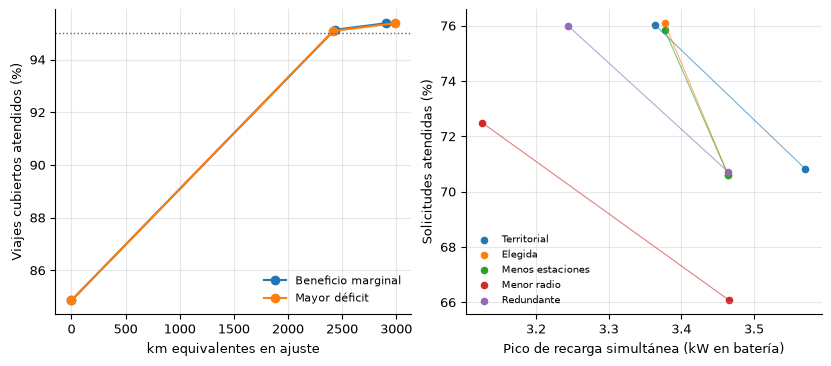

In [7]:
display(redes[["red", "periodo", "estaciones", "radio_m", "cubiertas", "n_atendido", "kwh_dia",
               "pico_red_kw", "pico_estacion_kw", "cuota_top10_pct"]].round(3))
fig, (izq, der) = plt.subplots(1, 2, figsize=(8.2, 3.55), layout="constrained")
for politica, grupo in ajuste.groupby("politica"):
    izq.plot(grupo["km_rebalanceo"], grupo["pct_atendidos_cubiertos"], marker="o",
             label={"beneficio": "Beneficio marginal", "deficit": "Mayor déficit"}[politica])
izq.axhline(objetivo_servicio, color="#526576", linewidth=1, linestyle=":")
izq.set(xlabel="km equivalentes en ajuste", ylabel="Viajes cubiertos atendidos (%)")
izq.legend(frameon=False)
nombres = {"habitual": "Elegida", "equidad": "Territorial", "redundante": "Redundante",
           "radio_menor": "Menor radio", "menos_estaciones": "Menos estaciones"}
for red, grupo in redes.groupby("red"):
    der.scatter(grupo["pico_red_kw"], grupo["pct_atendidos_total"], label=nombres[red], s=20)
    der.plot(grupo["pico_red_kw"], grupo["pct_atendidos_total"], linewidth=.8, alpha=.6)
der.set(xlabel="Pico de recarga simultánea (kW en batería)", ylabel="Solicitudes atendidas (%)")
der.legend(frameon=False, fontsize=7, loc="lower left")
guardar_figura(fig, "movilidad", "T39_cierre_movilidad")